<center><font size="4"><b>Technologia Mowy 2026</b></font></center>
<br />
<center><font size="6"><b><u>Lab 4: Modelowanie generatywne sygnału mowy</u></b></font></center>
<br />
<br />

<center><b>Notebook version:</b> 0.19 (5.11.2026)</center>
<center>Copyright Marcin Witkowski, AGH, 2026</center>


# Zadania

W poniższych zadaniach wykorzystaj modelowanie GMM oraz cechy MFCC aby stworzyć prosty klasyfikator rozróżniający 2 samogłoski - /i/ oraz /u/. Wykorzystaj nagrania o przedłużonej fonacji z poprzednich zajęć oraz nagraj nowe nagrania głosek /u/ oraz /i/ przez jednego z wcześniejszych mówców. Jeśli którekolwiek z posiadanych nagrań trwa krócej niż 3 sekundy, nagraj je ponownie.





Ustawienie środowiska (jeśli niepotrzebne to usuń pole):

In [94]:
from pathlib import Path
import gdown
import librosa
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
# Wczytaj audio

def download_data(url, data_dir="data"):
    data_dir = Path(data_dir)

    gdown.download_folder(
        url=url,
        output=str(data_dir),
        quiet=True
    )

    print("Pliki:", [p.name for p in data_dir.iterdir() if p.is_file() and p.name != ".gitkeep"])

    return data_dir


 W poniższym bloku kodu wykonaj parametryzację nagrań.


In [95]:
url = "https://drive.google.com/drive/folders/13SZHxIMs-u7HMwjGgsrefzx6AYWWO2KY?usp=drive_link"                         

files_path = download_data(url)
files = [p for p in files_path.iterdir() if p.name != ".gitkeep"]

print(files)

Pliki: ['I_Szymon.wav', 'I_wojtek.wav', 'U_Szymon.wav', 'U_wojtek.wav']
[WindowsPath('data/I_Szymon.wav'), WindowsPath('data/I_wojtek.wav'), WindowsPath('data/U_Szymon.wav'), WindowsPath('data/U_wojtek.wav')]


In [96]:
## oblicz macierze MFCC
out = {}
for file in files:
    y, sr = librosa.load(file, sr=16000)
    
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    sound_name = file.name.split('.')[0].upper()

    out[sound_name] = mfcc

#print(out["I_SZYMON"])

## 1. (2p) Analiza subiektywna modeli GMM


### 1.1 (0.2p) Trening modelu



Napisz funkcję, która przyjmuje jako argumenty wejściowe:
* macierz MFCC `mfcc`,
* wymaganą liczbę komponentów `n`,
* typ macierzy kowariancji `cov_type`,

oraz zwraca model GMM `gmm` o rozkładach dopasowanych do danych w `mfcc`. Funkcję wykorzystaj w następnych zadaniach.

In [97]:
from sklearn import mixture

def train_gmm(mfcc, n, cov_type):
    # Zmodyfikuj/uzupełnij ciało funkcji zgodnie z opisem powyżej
    gmm1 = mixture.GaussianMixture(n_components=n, covariance_type=cov_type,
                              tol=0.0000001, reg_covar=1e-02, max_iter=100,
                              n_init=1, init_params='random', # random
                              weights_init=None, means_init=None,precisions_init=None,
                              random_state=16, warm_start=False,
                              verbose=0, verbose_interval=1)
    return gmm1.fit(mfcc.T)

### 1.2 (1p) Jakościowa analiza dopasowania modelu do danych (kod umożliwiajacy wyświetlenie histogramów i dopasowanych rozkładów)

Korzystając z **jednego** wybranego nagrania (macierzy MFCC) i odpowiedniej funkcji wyświetl histogramy cech oraz nałożone na nie wypadkowe rozkłady gęstości prawdopodobieństwa dla modeli GMM o liczbie komponentów równych **1,2,4,8**. Do analizy wybierz **dwie** cechy (wymiary MFCC) dla których najlepiej będzie widoczne modelowanie wieloma komponentami Gaussa (czyli te o rozkładzie najmniej przypominającym normalny). Poniższy kod powinien generować 2 wykresy po 4 subploty (2 cechy, 4 modele).

W tym celu najpierw napisz funkcję, która rysuje histogram przyjmującą macierz MFCC `mfcc`, listę obiektów modeli GMM `gmms`, numer cechy `m`, która umożliwia wizualną (subiektywną) analizę podobieństwa modeli do danych. Dla każdego modelu w liście `gmms` funkcja powinna generować subplot, na którym zawarte będą:

*  histogram cechy o indeksie `m`,
*  dopasowane funkcje gęstości prawdopodobieństwa z modelu GMM dla każdego komponentu osobno (np osobnymi kolorami)
*  wypadkowy rozkład otrzymany jako suma rozkładów wszystkich komponentów.

Dla 4 i mniej modeli subplot'y powinny być wyświetlane horyzontalnie.

Po otrzymaniu wykresów subiektywnie oceń jakość modelowania w zależności od liczby komponentów na podstawie otrzymanych wykresów. Jaka liczba komponentów jest Twoim zdaniem wystarczająca by poprawnie modelować analizowane cechy?
Odpowiedź wpisz w bloku tekstu poniżej.

In [98]:
def plot_gmms_hist_fits(mfcc, gmms, m):
    data = mfcc[m]
    _, ax = plt.subplots(1, len(gmms), figsize=(4 * len(gmms), 3))
    if len(gmms) == 1:
        ax = [ax]

    bins_range = np.linspace(data.min(), data.max(), 300)
    
    pdf = lambda x, mu, sigma: ((1 / (np.sqrt(2 * np.pi) * np.maximum(sigma,1e-5))) * np.exp(-0.5 * ((x - mu) / np.maximum(sigma,1e-5))**2))

    for i, gmm in enumerate(gmms):
        ax[i].hist(data, bins=40, color='green', alpha=0.75, rwidth=0.85, density=True)
        ax[i].grid(axis='both', alpha=0.75)
        ax[i].set_xlabel('Value')
        ax[i].set_ylabel('Prob. density')
        ax[i].set_title(f"Liczba komponentów: {gmm.n_components}")
        
        total_pdf = np.zeros_like(bins_range)
        
        for k in range(gmm.n_components):
            mean = gmm.means_[k, m]
            
            if gmm.covariance_type == 'diag':
                sigma = np.sqrt(gmm.covariances_[k][m])
            else:
                sigma = np.sqrt(gmm.covariances_[k][m, m])
            
            comp_pdf = gmm.weights_[k] * pdf(bins_range, mean, sigma)
            total_pdf += comp_pdf
            
            ax[i].plot(bins_range, comp_pdf, '--', alpha=0.9)
            
        ax[i].plot(bins_range, total_pdf, color="red", lw=2, label="Suma GMM")
        ax[i].legend(fontsize=8)
        
    plt.tight_layout()
    plt.show()

c:\Users\szymo\Desktop\Studia\agh\semestr_5\Technologia mowy\Laboratorium\TM-Grupa-6\.venv\Lib\site-packages\sklearn\mixture\_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
c:\Users\szymo\Desktop\Studia\agh\semestr_5\Technologia mowy\Laboratorium\TM-Grupa-6\.venv\Lib\site-packages\sklearn\mixture\_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


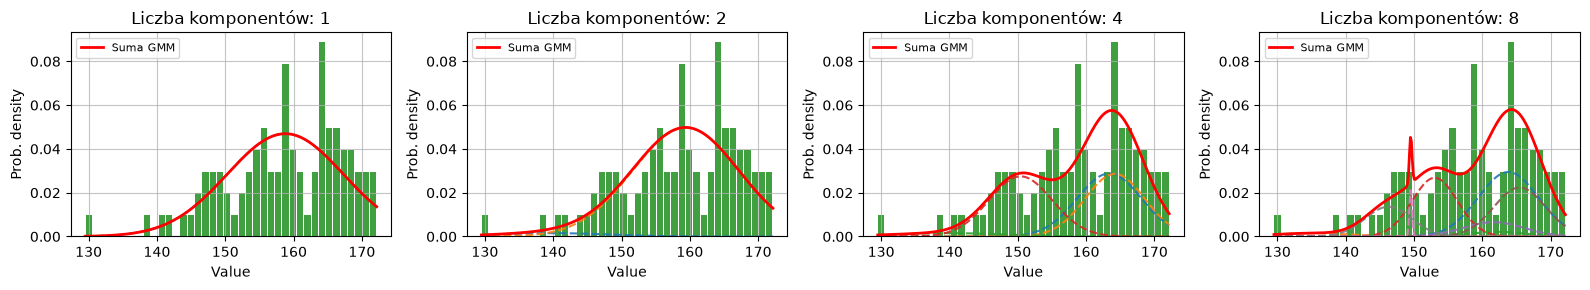

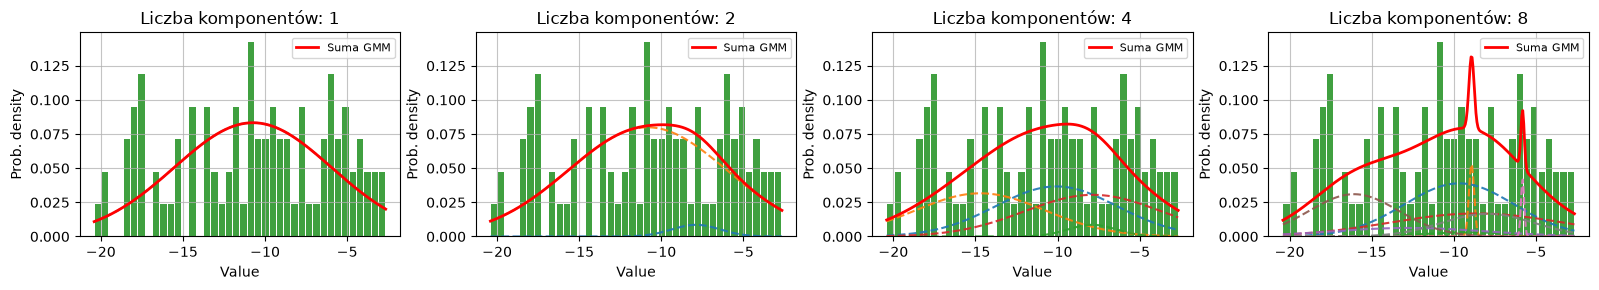

In [99]:
gmms_list = {}

mfcc = out["U_SZYMON"]
gmms_list =[
    train_gmm(mfcc, n=1, cov_type='diag'),
    train_gmm(mfcc, n=2, cov_type='diag'),
    train_gmm(mfcc, n=4, cov_type='diag'),
    train_gmm(mfcc, n=8, cov_type='diag')
]
  
plot_gmms_hist_fits(mfcc, gmms_list, m=1)
plot_gmms_hist_fits(mfcc, gmms_list, m=9)
# for cecha in range(len(mfcc)):
#     print(cecha)
#     plot_gmms_hist_fits(mfcc, gmms_list, m=cecha)

<font color="red">Uważam, że cztery komponenty to wystarczająca liczba, ponieważ odwzorowują one histogram cechy dokładniej niż dwa i w przeciwieństwie do ośmiu nie zachodzi dla niej efekt zbyt dużego wyuczenia się danych treningowych. </font>

### 1.3 (0.4p) Obiektywnnie najlepsza liczba komponentów

Ile komponentów jest obiektywnie optymalnych w modelowaniu pojedynczej głoski?
Narysuj gradient wartości [Bayesian Information Criterion (BIC)](https://medium.com/data-science/gaussian-mixture-model-clusterization-how-to-select-the-number-of-components-clusters-553bef45f6e4) w zależności od liczby komponentów i wskaż liczbę dla której następuje ustabilizowanie BIC. Opis tej obiektywnej metody oceny modelu poza innymi znajduje się [tutaj](https://medium.com/data-science/gaussian-mixture-model-clusterization-how-to-select-the-number-of-components-clusters-553bef45f6e4).

In [ ]:
#Miejsce na kod

### 1.4 (0.4p) Szybkość treningu modelu w zależności od ilości danych



Dla modeli o 8 oraz 16 komponentach wyświetl wykresy przedstawiające zależność log-podobieństwa (GaussianMixture.score()) w zależności od liczby ramek użytych do treningu modelu pojedynczej głoski (dla jednego mówcy). Kolejne punkty powinny wskazywać na osi X liczbę ramek użytych do treningu modelu, więc w praktyce wykonaj wielokrotnie trening korzystając z coraz większej ilości danych treningowych. W ramach zadania powinny powstać 2 wykresy (dla modeli o 8 i 16 komponentach). Następnie na podstawie wykresów oszacuj minimalną liczbę ramek umożliwiajacą utworzenie modelu. Jeśli szacowanie jest niemożliwe uzasadnij to w odpowiedzi.

**Uwaga**: Warto wymusić podczas inicjalizacji modelu:
- (1) losowe parametry (zamiast estymowanych za pomocą K-means) oraz
- (2) ustalić stały parametr korzenia losowego (seed) w celu powtarzalności generowanego wykresu.

In [ ]:
# Miejsce na kod

<font color="red">Wniosek</font>

## 2. (1p) Klasyfikator Bayesa

### 2.1 (0.5p) Wyznaczanie średnich wartości log-podobieństwa

Na podstawie modeli GMM uzyskanych w zadaniu 1 dla jednego mówcy wyznacz średnie log-podobieństwa (loglikelihood):
* log(p(MFCC_U | GMM_U)) (jak nagranie U pasuje do modelu U),
* log(p(MFCC_I | GMM_U)) (jak nagranie I pasuje do modelu U),
* log(p(MFCC_I | GMM_I)) (jak nagranie I pasuje do modelu I),
* log(p(MFCC_U | GMM_I)) (jak nagranie U pasuje do modelu I).

Następnie odpowiedz na pytania:
1. Omów uzyskane wartości - czy są one zgodne z oczekiwaniami?
2. Wybierając klasę na podstawie najwyższego log-podobieństwa posługujesz się *naiwnym* klasyfikatorem Bayesa. Opisz **własnymi słowami** dlaczego konkretnie ten klasyfikator w tym kontekście jest nazywany *naiwnym*.


In [ ]:
# Miejsce na kod

<font color="red"> Odpowiedź </font>

### 2.2 (0.5p) Reguła Bayesa



Korzystając z reguły Bayesa oblicz 4 prawdopodobieństwa (P(GMM_x/MFCC_y)) dla nowo utworzonych nagrań głosek /u/ oraz /i/ dla tego samego mówcy  oraz dla innego mówcy. Przyjmij równe prawdopodobieństwa a priori klas. Na podstawie obliczonych wartości odpowiedz na pytania:
1. Czy nowe nagranie /u/ tego samego mówcy uzyskuje wyższe prawdopodobieństwo klasyfikacji jako /u/ czy jako /i/? Omów uzyskane wyniki.
2. Czy nagranie /u/ innego mówcy uzyskuje wyższe prawdopodobieństwo klasyfikacji jako /u/ czy jako /i/?

Bloki kodu i tekstu zorganizuj tak by rozwiązanie całego zadania **było czytelne.**


In [ ]:
# Oblicz prawdopodobieństwa

<font color="red"> Odpowiedź </font>

# Ocena
### <font color="orange"> * Przed ostatecznym zapisem usuń bloki zawierające gwiazdkę (*) w tytule. </font>

### * 1 termin tego zadania upływa **10.11.2026 o godz. 13:00**. Po skończonej pracy należy zapisać plik opcją `File > Save and pin revision`. Prowadzący oceniając odtworzy ostanią wersję w repozytorium notatnika sprzed daty oddania i ta wersja będzie podlegać ocenie.